# Corpus Analysis — Milestone 1 (arXiv crawl)

This notebook profiles the corpus produced by the crawler in `src/`. It belongs to the Milestone 1 report and is meant to be **re-executed when the Jupyter Book is compiled**, so that every table and figure is generated from the crawled data and not pasted as a screenshot.

**What is analysed**

1. **Scope** — the assigned ID range, how many papers and versions were crawled, and which IDs failed.
2. **Record structure** — one JSON object per paper in `papers.jsonl`, flattened into two summary tables: `papers_summary` (one row per paper) and `versions_summary` (one row per version). It is also compared with the `papers` / `references` tables required by the project statement.
3. **Data quality** — value types, missing fields, crawl completeness and what the corpus stores on disk.
4. **Content statistics** — versions per paper, references per paper, categories and authors.

Each section ends with **Findings**, and the last section lists the **actions** that follow for Milestones 2 (parsing) and 3 (matching).

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from utils.build_summary import build_book_summaries

sns.set_theme(style="whitegrid", palette="muted")

# Paths are relative to this notebook. The data folder is NOT part of the code repository.
DATA_DIR = Path("../data")
PAPERS_JSONL = DATA_DIR / "metadata" / "papers.jsonl"
FAILURES_JSONL = DATA_DIR / "metadata" / "failures.jsonl"
IDS_FILE = DATA_DIR / "inputs" / "arxiv_ids.txt"
RAW_DIR = DATA_DIR / "raw"
SUMMARY_DIR = DATA_DIR / "summary"

In [ ]:
def read_jsonl(file_path):
    """Yield one parsed record per non-empty line of a JSON Lines file."""
    with open(file_path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                yield json.loads(line)


# Build the per-paper and per-version summary tables, then load everything.
build_book_summaries(str(PAPERS_JSONL), str(SUMMARY_DIR))

papers = list(read_jsonl(PAPERS_JSONL))
df_papers = pd.read_parquet(SUMMARY_DIR / "papers_summary.parquet")
df_versions = pd.read_parquet(SUMMARY_DIR / "versions_summary.parquet")

## Scope and crawl success

In [ ]:
# Assigned IDs = every ID the crawler generated into arxiv_ids.txt
assigned_ids = (
    [line.strip() for line in IDS_FILE.read_text().splitlines() if line.strip()]
    if IDS_FILE.exists()
    else []
)
crawled_ids = {p["arxiv_id"] for p in papers}
failures = list(read_jsonl(FAILURES_JSONL)) if FAILURES_JSONL.exists() else []
failed_ids = {f["arxiv_id"] for f in failures} - crawled_ids  # an ID retried later may have succeeded

n_assigned = len(assigned_ids) or len(crawled_ids)
n_crawled = len(crawled_ids)
n_failed = len(failed_ids)
n_untracked = max(n_assigned - n_crawled - n_failed, 0)
ids_for_range = assigned_ids or sorted(crawled_ids)

scope = pd.DataFrame(
    {
        "Metric": [
            "First ID",
            "Last ID",
            "Assigned IDs",
            "Papers crawled (in papers.jsonl)",
            "Versions crawled",
            "Failed IDs (logged in failures.jsonl)",
            "Never attempted / not logged",
            "Paper-level success rate (%)",
        ],
        "Value": [
            ids_for_range[0],
            ids_for_range[-1],
            f"{n_assigned:,}",
            f"{n_crawled:,}",
            f"{sum(len(p['versions']) for p in papers):,}",
            f"{n_failed:,}",
            f"{n_untracked:,}",
            f"{n_crawled / n_assigned * 100:.2f}",
        ],
    }
)
display(scope)

if failures:
    fail_df = pd.DataFrame(failures).drop_duplicates("arxiv_id", keep="last")
    fail_df = fail_df[fail_df["arxiv_id"].isin(failed_ids)]
    # Collapse per-version steps ("Extracting references for v2") and IDs inside messages
    fail_df["step"] = fail_df["failed_step"].str.replace(r"\s+(for\s+)?v\d+$", "", regex=True)
    fail_df["error"] = (
        fail_df["error_message"]
        .str.replace(r"\d{4}\.\d{4,5}(v\d+)?", "<ID>", regex=True)
        .str.slice(0, 90)
    )
    print("Failed IDs by crawler step")
    display(fail_df["step"].value_counts().to_frame("failed_ids"))
    print("Most frequent error messages (IDs normalised)")
    display(fail_df["error"].value_counts().head(5).to_frame("failed_ids"))

**How to read the table**

- `Assigned IDs` is the number of IDs written to `arxiv_ids.txt` by the ID generator; `Papers crawled` are the IDs that reached `papers.jsonl`; `Failed IDs` come from `failures.jsonl`.
- The *step* table shows where a paper was lost (version probing, metadata call, or an unexpected error) and the error table shows why. IDs that fail at the probing step with "No versions found" are IDs that do not exist or were removed — these are not crawler bugs.
- `Never attempted / not logged` should be **0**. If it is not, the run was interrupted or an error escaped the logger; run the crawler again (it resumes from `papers.jsonl`).
- The success rate is measured per **paper**. Missing LaTeX sources inside a paper that *was* crawled are audited separately in *Crawl completeness*.

## Record structure
A tree view of one record from `papers.jsonl` (keys only, values hidden):

In [20]:
def print_tree(data, indent_level=0, indent_char="\t", print_item=True):
    """
    Recursively prints a nested dictionary/list structure as an indented tree.
    """
    indent = indent_char * indent_level

    if isinstance(data, dict):
        for key, value in data.items():
            if isinstance(value, (dict, list)):
                print(f"{indent}{key}:")
                print_tree(value, indent_level + 1, indent_char, print_item)
            else:
                print(f"{indent}{key}: {value if print_item else ''}")

    elif isinstance(data, list):
        for index, item in enumerate(data):
            if isinstance(item, (dict, list)):
                print(f"{indent}[{index}]:")
                print_tree(item, indent_level + 1, indent_char, print_item)
            elif print_item:
                print(f"{indent}- {item}")
    else:
        print(f"{indent}{data if print_item else ''}")


print_tree(papers[0], print_item=False)

arxiv_id: 
versions:
	[0]:
		version: 
		metadata:
			title: 
			authors:
			abstract: 
			categories:
			submission_date: 
		latex_source_path: 
		raw_references:


Each line of `papers.jsonl` is one **publication** with this hierarchy:

- `arxiv_id` — the base ID, without a version suffix.
- `versions[]` — one entry per crawled version (`v1`, `v2`, …), in order. Each entry has:
  - `version` — the suffix, e.g. `v2`;
  - `metadata` — `title`, `authors` (list), `abstract`, `categories` (list) and `submission_date` from the arXiv API;
  - `latex_source_path` — the folder with the extracted source of that version, or `null` when no source could be downloaded or extracted. The version is **kept with an empty record** rather than dropped, as the project statement requires for PDF-only submissions;
  - `raw_references` — the raw `\bibitem` strings found in the version's `.bbl` or `thebibliography` environment (empty list when none was found).

The first view hides values so the *shape* is easy to see. The next cell prints a real multi-version paper with long strings and lists shortened.

In [ ]:
def shorten(obj, max_str=70, max_items=2):
    """Return a copy of a nested record with long strings cut and long lists trimmed."""
    if isinstance(obj, dict):
        return {k: shorten(v, max_str, max_items) for k, v in obj.items()}
    if isinstance(obj, list):
        trimmed = [shorten(v, max_str, max_items) for v in obj[:max_items]]
        if len(obj) > max_items:
            trimmed.append(f"... (+{len(obj) - max_items} more)")
        return trimmed
    if isinstance(obj, str) and len(obj) > max_str:
        return obj[:max_str] + "..."
    return obj


example = next((p for p in papers if len(p["versions"]) >= 2), papers[0])
print(json.dumps(shorten(example), indent=2, ensure_ascii=False))

### Conformance with the tables required by the project statement

| Required column | Where it comes from in our records | Status |
|---|---|---|
| `papers.arxiv_id` | `arxiv_id` | OK |
| `papers.title` | `versions[].metadata.title` | OK |
| `papers.authors` | `versions[].metadata.authors` | OK |
| `papers.submission_date` | `versions[0].metadata.submission_date` | OK (date of v1) |
| `papers.revised_dates` | `versions[1:].metadata.submission_date` | **Wrong values** — every version carries the v1 date, see *Version and revision analysis* |
| `papers.venue` | not collected (`arxiv:journal_ref` is in the API response but not parsed) | **Missing** |
| `references.*` (`ref_arxiv_id`, `ref_title`, `ref_authors`, `ref_submission_date`, `ref_s2_id`) | not collected — we only hold `raw_references` strings parsed from LaTeX | **Missing** — needs the Semantic Scholar crawl |

Extra fields we keep (`abstract`, `categories`, `latex_source_path`, `raw_references`) are harmless and useful for Milestone 2, but they do not replace the required columns above.

## Check for Value Type

**What the next cell does.** Before analysing anything, it checks that the tables loaded from Parquet have the types the later cells rely on:

1. it lists every column of the version table that contains missing values (columns with no missing values are hidden);
2. for four columns — `metadata.categories`, `metadata.submission_date`, `num_categories` and `submission_dt` — it prints which Python types occur and two example values.

**What we expect to see.** Only `latex_source_path` should have missing values. `metadata.categories` should be an array, the raw date an ISO-8601 string, and the derived `submission_dt` a timezone-aware UTC timestamp, so dates can be compared and subtracted safely.

In [33]:
print("=== Missing values in original version-level data ===")
display(
    df_versions.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
    .query("missing_count > 0")
)


cols = [
    "metadata.categories",
    "metadata.submission_date",
    "num_categories",
    "submission_dt"
]

for col in cols:
    print(f"\n{col}")
    print("Data types:")
    print(df_versions[col].map(type).value_counts().head())
    print("Examples:")
    print(df_versions[col].head(2).tolist())

=== Missing values in original version-level data ===


,missing_count
latex_source_path,965



metadata.categories
Data types:
metadata.categories
<class 'numpy.ndarray'>    6573
Name: count, dtype: int64
Examples:
[array(['hep-ph', 'astro-ph.CO'], dtype=object), array(['hep-ph', 'astro-ph.CO'], dtype=object)]

metadata.submission_date
Data types:
metadata.submission_date
<class 'str'>    6573
Name: count, dtype: int64
Examples:
['2024-08-28T18:00:00Z', '2024-08-28T18:00:00Z']

num_categories
Data types:
num_categories
<class 'int'>    6573
Name: count, dtype: int64
Examples:
[2, 2]

submission_dt
Data types:
submission_dt
<class 'pandas.Timestamp'>    6573
Name: count, dtype: int64
Examples:
[Timestamp('2024-08-28 18:00:00+0000', tz='UTC'), Timestamp('2024-08-28 18:00:00+0000', tz='UTC')]


**Findings**

- The only column with missing values is `latex_source_path` (965 of 6,573 versions). This is a crawl gap rather than a schema problem and is audited in the next section.
- Every column holds a single type (no mixed `str` / `float` values), so no cleaning step is needed before the analysis.
- `metadata.categories` is a NumPy array after the Parquet round trip, so category counts need `explode()` or the `primary_category` column of the paper table.
- Look at the two example dates: the first two rows look like two versions of the same paper, yet they carry the **same timestamp**. This is not a formatting issue — it is the date problem analysed in *Version and revision analysis*.

## Crawl Completeness & Missing-Field audit

**Purpose of this check.** For every crawled *version*, count which required parts are absent: the metadata fields (title, categories, submission date), the LaTeX source, and the extracted bibliography. Percentages are relative to all crawled versions.

**What we should discover**

- Metadata should be complete, because it comes from the arXiv API and every paper has it.
- Only a small share of versions without source. The project statement says arXiv provides source for about 97% of submissions, so we should expect roughly 3% PDF-only versions.
- Some versions that *have* source but produce no references — a signal of the limits of our `\bibitem` extractor.

In [ ]:
# Identify valid source paths directly from latex_source_path
valid_source_mask = (
    df_versions["latex_source_path"].notna() 
    & (df_versions["latex_source_path"].astype(str).str.strip() != "")
)

audit_metrics = {
    "Missing Title": df_versions["metadata.title"].isna().sum(),
    "Empty Categories": (df_versions["num_categories"] == 0).sum(),
    "Missing Submission Date": df_versions["submission_dt"].isna().sum(),
    "Missing LaTeX Source Path (PDF-only / Withdrawn)": (~valid_source_mask).sum(),
    "Has Source Path, But 0 Extracted \\bibitem Refs": (valid_source_mask & (df_versions["num_raw_refs"] == 0)).sum(),
    "Total Versions with 0 Extracted \\bibitem Refs": (df_versions["num_raw_refs"] == 0).sum(),
}

audit_df = pd.DataFrame([
    {
        "Metric / Field Check": k,
        "Affected Versions": int(v),
        "Percentage (%)": round(v / len(df_versions) * 100, 2),
    }
    for k, v in audit_metrics.items()
])
display(audit_df)

,Metric / Field Check,Affected Versions,Percentage (%)
0,Missing Title,0,0.00
1,Empty Categories,0,0.00
2,Missing Submission Date,0,0.00
3,Missing LaTeX Source Path (PDF-only / Withdrawn),965,14.68
4,"Has Source Path, But 0 Extracted \bibitem Refs",396,6.02
5,Total Versions with 0 Extracted \bibitem Refs,1361,20.71


**Findings**

- **Metadata is complete.** `Missing Title`, `Empty Categories` and `Missing Submission Date` are all 0 because these fields come straight from the arXiv API. Complete does not mean *correct*: see the date problem below.
- **965 versions (14.68%) have no LaTeX source.** The table labels them "PDF-only / Withdrawn", but that is an assumption. The crawler catches every error of the download step, prints a warning and stores `null`, so a genuine PDF-only submission, a withdrawn paper, a timeout and a source that is not a `.tar.gz` (for example a single gzipped `.tex` file) all look identical. Since the expected PDF-only rate is about 3%, a rate near five times higher suggests that a large part of these versions are **recoverable crawl failures** and not missing data.
- **396 versions (6.02%) have a source but no extracted reference.** Plausible causes: a `.bib` file without a shipped `.bbl`, `biblatex` output (no `thebibliography` environment), a bibliography `\input` from another file, or a paper without references. The extractor also reads only the first `.bbl` it finds.
- **1,361 versions (20.71%) have zero extracted references.** This is exactly `965 + 396`: a version without source always has an empty reference list, so the two causes add up.
- **Impact.** More than one version in five cannot contribute to the `references` table and 14.68% cannot be parsed in Milestone 2. Improving the source step first is the best return on effort because it feeds both numbers. For references, Semantic Scholar does not depend on LaTeX and can cover versions whose source is missing.

In [ ]:
# The same audit at paper level: how many *papers* are affected, not only versions?
paper_audit = pd.DataFrame(
    {
        "Check": [
            "Papers with no LaTeX source in any version",
            "Papers whose latest version has 0 extracted references",
        ],
        "Papers": [
            int((df_papers["versions_with_source"] == 0).sum()),
            int((df_papers["latest_refs"] == 0).sum()),
        ],
    }
)
paper_audit["Percentage (%)"] = (paper_audit["Papers"] / len(df_papers) * 100).round(2)
display(paper_audit)

### What the corpus stores on disk

The project statement keeps **only `.tex` and `.bib` files** in the corpus (figure binaries and other files must never enter it). The next cell inventories `data/raw` by file extension, reports the corpus size, and counts how much is *not* `.tex` / `.bib`.

In [ ]:
INVENTORY_FILE = SUMMARY_DIR / "corpus_inventory.parquet"

if RAW_DIR.exists():
    inventory = pd.DataFrame(
        [(p.suffix.lower() or "(none)", p.stat().st_size) for p in RAW_DIR.rglob("*") if p.is_file()],
        columns=["extension", "bytes"],
    )
    inventory.to_parquet(INVENTORY_FILE)  # lets the book be built without the raw folder
elif INVENTORY_FILE.exists():
    inventory = pd.read_parquet(INVENTORY_FILE)
else:
    inventory = None
    print("No raw corpus or saved inventory found: skipping the on-disk analysis.")

if inventory is not None:
    n_versions_with_source = int(df_versions["latex_source_path"].notna().sum())
    total_bytes = int(inventory["bytes"].sum())
    non_source_bytes = int(inventory.loc[~inventory["extension"].isin([".tex", ".bib"]), "bytes"].sum())

    by_ext = (
        inventory.groupby("extension")["bytes"]
        .agg(files="count", total_bytes="sum")
        .sort_values("total_bytes", ascending=False)
    )
    by_ext["share_of_bytes_%"] = (by_ext["total_bytes"] / total_bytes * 100).round(2)

    print(f"Corpus size on disk (after figure removal): {total_bytes / 1e6:,.1f} MB")
    print(f"Average per crawled paper:                  {total_bytes / len(df_papers) / 1e3:,.1f} kB")
    print(f"Average per version with source:            {total_bytes / n_versions_with_source / 1e3:,.1f} kB")
    print(f"Bytes in files other than .tex/.bib:        {non_source_bytes / total_bytes:.1%}")
    display(by_ext.head(10))

    fig, ax = plt.subplots(figsize=(7, 3.5))
    top = by_ext.head(8)
    sns.barplot(x=top["total_bytes"] / 1e6, y=top.index, ax=ax, color="slategray")
    ax.set_title("Corpus size by file extension (top 8)")
    ax.set_xlabel("Size (MB)")
    ax.set_ylabel("Extension")
    plt.tight_layout()
    plt.show()

**How to read it.** In a corpus that follows the statement, `.tex` and `.bib` should account for essentially all files. Any other extension (`.sty`, `.cls`, `.bst`, `.bbl`, `.svg`, `.tikz`, …) means the cleaning step deleted a fixed list of image extensions instead of extracting only the wanted file types, so non-figure files are still stored.

**Not measured here:** the size *before* figure removal. The crawler deletes the downloaded archive and does not record its size, so the "average paper size in bytes before and after removing figures" required by the report must be measured separately (for instance by re-downloading a random sample of papers and recording the archive size and the extracted `.tex` + `.bib` size).

## Version and revision analysis

In [ ]:
print("=== Summary Statistics Across Unique Papers ===")
display(
    df_papers[["num_versions", "num_authors", "abstract_words", "latest_refs", "revision_span_days"]]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.99])
    .T.round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot 1: Number of Versions per Paper
v_counts = df_papers["num_versions"].value_counts().sort_index()
sns.barplot(x=v_counts.index, y=v_counts.values, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of Paper Versions (v1 to vN)")
axes[0].set_xlabel("Total Versions per Paper")
axes[0].set_ylabel("Number of Papers")

# Plot 2: Revision span in days (papers with >= 2 versions)
multi_v = df_papers[df_papers["num_versions"] >= 2]
span = multi_v["revision_span_days"].dropna()
if span.max() == 0:
    # Every version carries the v1 date, so the span is meaningless (see the findings below).
    axes[1].text(
        0.5, 0.5,
        "All revision spans are 0 days\n(data issue: every version stores the v1 date)",
        ha="center", va="center", transform=axes[1].transAxes,
    )
    axes[1].set_axis_off()
else:
    sns.histplot(span, bins=25, kde=True, ax=axes[1], color="teal")
    axes[1].set_xlabel("Revision Span (Days)")
    axes[1].set_ylabel("Number of Papers")
axes[1].set_title("Time Span Between v1 and Latest Version (Multi-Version Papers)")

plt.tight_layout()
plt.show()

In [ ]:
# Exact share of papers per number of versions (the bars above, as numbers)
share = df_papers["num_versions"].value_counts(normalize=True).sort_index().mul(100).round(1)
display(share.to_frame("share_of_papers_%").T)

# Date check: do the versions of a paper really have different submission dates?
multi_papers = [p for p in papers if len(p["versions"]) >= 2]
if multi_papers:
    same_date = sum(
        len({v["metadata"]["submission_date"] for v in p["versions"]}) == 1 for p in multi_papers
    )
    print(f"Multi-version papers: {len(multi_papers):,}")
    print(f"... whose versions ALL share one submission_date: {same_date:,} ({same_date / len(multi_papers):.1%})")
    example_dates = [(v["version"], v["metadata"]["submission_date"]) for v in multi_papers[0]["versions"]]
    print(f"Example, {multi_papers[0]['arxiv_id']}: {example_dates}")

**Findings**

- **Most papers are never revised.** The median is 1 version; 75% of papers have at most 2 versions, 90% at most 3 and 99% at most 5 (maximum 10). The mean is 1.61, so the 4,087 papers expand to 6,573 versions: the *every-version* requirement costs on average 1.6 source downloads per paper.
- Roughly 1,150 papers have exactly two versions and about 350 have three (exact shares in the table above); only about 170 papers have four or more.
- **The right-hand panel is not valid yet.** Every multi-version paper (about 1,700 papers) shows a revision span of exactly 0 days, and the date check confirms that all versions of a paper share one timestamp. Real revisions are separated by days or months, so this is a **data-collection bug, not a property of the corpus**. `metadata.py` stores the Atom `<published>` element, which the arXiv API defines as the submission date of **version 1** whatever version is requested; the date of the requested version is in `<updated>`. As a result `revised_dates` — a required column of the `papers` table — is wrong for every revised paper.
- **Fix:** read `<updated>` for each version (and `<arxiv:journal_ref>` for the venue, which is also still missing) and re-fetch the metadata only. This takes one batched API request per roughly 100 versions and does not require downloading any source again. The plot above fills in automatically once the data is corrected.

## Reference & Citation Distribution Analysis

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Filter to papers where at least one version had a valid latex_source_path
valid_src = df_papers[df_papers["versions_with_source"] > 0]

# Plot 1: Distribution of Reference Counts (Latest Version)
sns.histplot(valid_src["latest_refs"], bins=30, kde=True, ax=axes[0], color="coral")
axes[0].set_title("Extracted References per Paper (Latest Version)")
axes[0].set_xlabel("Number of Extracted References")
axes[0].set_ylabel("Paper Count")

# Plot 2: Net change in references from v1 to the latest version (revised papers with refs in v1)
revised_with_refs = valid_src[(valid_src["num_versions"] >= 2) & (valid_src["v1_refs"] > 0)]
sns.histplot(revised_with_refs["ref_growth"], bins=20, kde=False, ax=axes[1], color="slateblue")
axes[1].set_title("Net Reference Change Between v1 and Latest Version")
axes[1].set_xlabel("Net Reference Change (Latest Refs - v1 Refs)")
axes[1].set_ylabel("Paper Count")

plt.tight_layout()
plt.show()

In [ ]:
print("Extracted references per paper, latest version (papers with at least one source version)")
display(valid_src["latest_refs"].describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_frame("value").T)
print(f"Papers with 0 extracted references despite having a source: {(valid_src['latest_refs'] == 0).mean():.1%}")
print(
    f"Revised papers whose reference count did not change: "
    f"{(revised_with_refs['ref_growth'] == 0).mean():.1%} of {len(revised_with_refs):,}"
)

**Findings**

- **Left panel:** the number of extracted references per paper is strongly right-skewed. Over all 4,087 papers the median is 34, the mean 40.8, the 90th percentile 83 and the 99th percentile 193, with a maximum of 741. The first bar is inflated by papers whose bibliography could not be extracted (see the audit above).
- **Right panel:** for revised papers the net change in references is zero or close to zero for most of them (the tall central bar), with both increases and decreases. A decrease does not necessarily mean citations were removed: a newer version may move from a `.bbl` to `biblatex` / `.bib`, which our extractor cannot read, so part of the spread is extraction noise.
- **Caveat:** these are counts of raw `\bibitem` strings, not resolved citations. They overstate the number of *resolvable* references (some entries are books, URLs or software) and understate it for papers whose bibliography was not parsed. The reference count that matters for Milestone 3 — references with an arXiv ID — can only come from the Semantic Scholar crawl.

## Category & Author Distribution

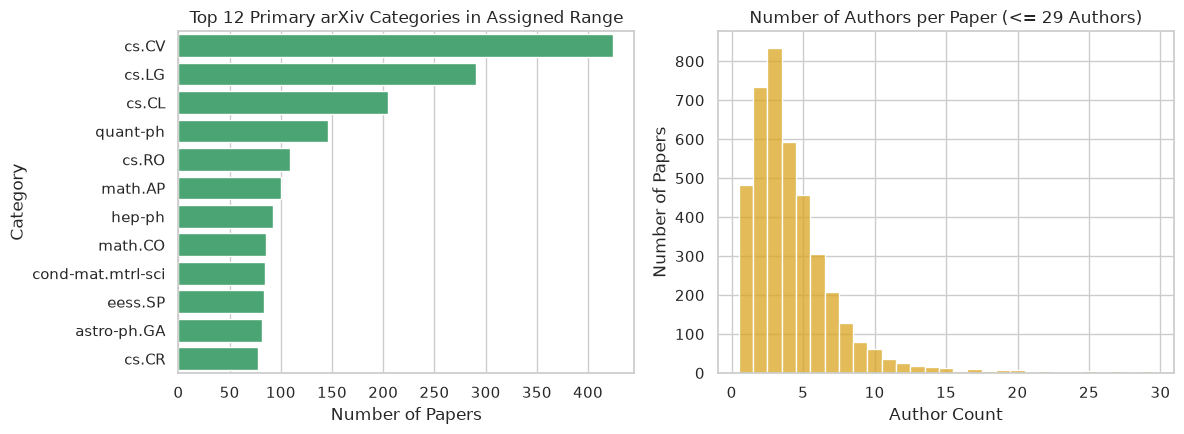

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Top 12 Primary Categories
top_cats = df_papers["primary_category"].value_counts().head(12)
sns.barplot(x=top_cats.values, y=top_cats.index, ax=axes[0], color="mediumseagreen")
axes[0].set_title("Top 12 Primary arXiv Categories in Assigned Range")
axes[0].set_xlabel("Number of Papers")
axes[0].set_ylabel("Category")

# Author Count Distribution (Clipped at 99th percentile for readability)
q99 = df_papers["num_authors"].quantile(0.99)
sns.histplot(df_papers[df_papers["num_authors"] <= q99]["num_authors"], discrete=True, ax=axes[1], color="goldenrod")
axes[1].set_title(f"Number of Authors per Paper (<= {int(q99)} Authors)")
axes[1].set_xlabel("Author Count")
axes[1].set_ylabel("Number of Papers")

plt.tight_layout()
plt.show()

In [ ]:
cat_counts = df_papers["primary_category"].value_counts()
top12 = cat_counts.head(12)
print(f"Distinct primary categories: {len(cat_counts)}")
print(f"Top-12 categories cover {top12.sum():,} of {len(df_papers):,} papers ({top12.sum() / len(df_papers):.1%})")

archive = df_papers["primary_category"].str.split(".").str[0]
display(archive.value_counts(normalize=True).mul(100).round(1).head(8).to_frame("share_of_papers_%").T)

authors = df_papers["num_authors"]
print(f"Single-author papers: {(authors == 1).mean():.1%}")
print(f"Median / mean number of authors: {authors.median():.0f} / {authors.mean():.2f}")
print(f"Papers with >= 100 authors (large collaborations): {(authors >= 100).sum():,}")

**Findings — categories (left panel)**

- Of the twelve most frequent primary categories, five belong to computer science (`cs.CV`, `cs.LG`, `cs.CL`, `cs.RO`, `cs.CR`), four to physics (`quant-ph`, `hep-ph`, `cond-mat.mtrl-sci`, `astro-ph.GA`), two to mathematics (`math.AP`, `math.CO`) and one to electrical engineering and systems science (`eess.SP`).
- Machine-learning subfields dominate: `cs.CV` is the single largest category, followed by `cs.LG` and `cs.CL`.
- The distribution has a long tail: the twelve categories above cover only a minority of the papers (the exact share is printed above), so most of the corpus is spread over many small categories. The corpus is a contiguous ID range from one period, not a random sample of arXiv, so these shares should not be generalised to arXiv as a whole.
- **Why it matters.** Physics, mathematics and computer science use different bibliography tooling and conventions. Testing whether the 396 "source but no references" versions concentrate in particular categories is a cheap first step in Milestone 2 (hypothesis, not yet verified).

**Findings — authors (right panel, clipped at the 99th percentile = 29 authors)**

- The distribution is right-skewed: median 3 authors, 75% of papers have at most 5 and 90% at most 8. The mean (6.59) is pulled up by a few very large collaborations (maximum 1,140 authors).
- The most common team size is 3 authors; single-author papers are about 12% of the corpus.
- **Why it matters.** A few papers carry hundreds of authors, which makes author lists a weak and expensive matching key for such papers in Milestone 3. Title and arXiv ID are better primary keys; authors are best used as a secondary signal.

## Summary and actions

| # | Finding | Evidence | Action | Affects |
|---|---|---|---|---|
| 1 | All versions of a paper share the v1 date | Revision span is 0 for every multi-version paper | Read `<updated>` per version, re-fetch metadata only | `revised_dates`, Milestones 2–3 |
| 2 | 14.68% of versions have no source, and the reason is not recorded | 965 versions; about 3% expected | Download from the `export.arxiv.org/src/` mirror, handle non-tar sources, log a failure reason per version, retry | Milestone 2 (parsing) |
| 3 | 20.71% of versions have no extracted references | 965 without source + 396 with source | Support `biblatex` / `.bib`, then add the Semantic Scholar crawl | Milestone 3 (matching), `references` table |
| 4 | `venue` and all Semantic Scholar fields are missing | Schema table above | Parse `arxiv:journal_ref`; crawl references with `externalIds.ArXiv` | `papers` and `references` tables |
| 5 | Files other than `.tex` / `.bib` are kept | On-disk inventory | Extract only `.tex` and `.bib` instead of deleting images afterwards | Corpus size, convention conformance |
| 6 | Size before figure removal is not recorded | Archive is deleted after extraction | Log archive and extracted sizes in the crawler | Report statistics |

**Limitations of this analysis.** Reference counts are raw `\bibitem` counts; "no source" mixes real PDF-only submissions with crawl failures; and the date-based statistics are unreliable until item 1 is fixed. Numbers quoted in the text come from the run shown in this notebook and must be refreshed if the crawl is repeated.